# Customer Churn: Training and Evaluating Baseline Models

## The dataset

`customer_churn.csv` is the Iranian Churn Dataset, collected from an Iranian telecom provider and aggregated over a 12 month period. Each row is one customer, and the columns summarise how much they used the service, what plan they were on, and whether they left by the end of the period.

**3150 rows, 14 columns**, which is 13 features and one binary target. The target is `Churn`, so this is a binary classification problem. 15.7% of customers churned, which makes the classes imbalanced at roughly 5.4 to 1.

All columns are numeric, and there are no missing values.

## The features

**Usage behaviour**

| Feature | Range | Meaning |
|---|---|---|
| `Call Failure` | 0 to 36 | Number of failed calls |
| `Seconds of Use` | 0 to 17090 | Total seconds spent on calls |
| `Frequency of use` | 0 to 255 | Total number of calls made |
| `Frequency of SMS` | 0 to 522 | Total number of text messages sent |
| `Distinct Called Numbers` | 0 to 97 | How many different numbers the customer called |

**Account and plan**

| Feature | Range | Meaning |
|---|---|---|
| `Subscription Length` | 3 to 47 | Months subscribed |
| `Charge Amount` | 0 to 10 | Ordinal band, 0 is the lowest charge and 10 the highest |
| `Tariff Plan` | 1, 2 | Documented as 1 = pay as you go, 2 = contractual |
| `Status` | 1, 2 | Documented as 1 = active, 2 = non-active |
| `Complains` | 0, 1 | 1 if the customer made a complaint. 7.7% of rows |

**Customer**

| Feature | Range | Meaning |
|---|---|---|
| `Age` | 15 to 55 | Customer age. Only 5 distinct values appear |
| `Age Group` | 1 to 5 | Ordinal age band |

**Derived**

| Feature | Range | Meaning |
|---|---|---|
| `Customer Value` | 0 to 2165.28 | A value score calculated by the provider rather than measured directly |

**Target**

| Feature | Values | Meaning |
|---|---|---|
| `Churn` | 0, 1 | 1 if the customer left. 15.7% of rows |

The meanings of `Tariff Plan`, `Status`, `Charge Amount` and `Age Group` come from the dataset documentation rather than from the data itself, since the file contains only the coded values.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import SGDClassifier

## 1. Exploratory Data Analysis

### 1.1 Loading the data

Three headers in the raw CSV contain double spaces: `Call  Failure`, `Subscription  Length` and `Charge  Amount`. They are collapsed to single spaces so column lookups do not raise `KeyError`.

Regex is used rather than retyping all 14 names. Retyping would work, but a mistake in the order would silently mislabel columns with no error, while the regex fixes only the spacing and cannot reorder anything.

`info()` confirms 3150 rows, 14 columns, no nulls, all numeric.

In [2]:
#Read the data from the csv file
customer_churn_data = pd.read_csv('customer_churn.csv')
#the column names have double spaces, which might give me KeyError exceptions down the line when i try to index with the names
#using only 1 space, removing the extra spaces here with regex.
customer_churn_data.columns = customer_churn_data.columns.str.replace(r'\s+', ' ', regex=True).str.strip()
#showing info of the dataframe
customer_churn_data.info()
#showing the first 5 rows.
customer_churn_data.head()



<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call Failure             3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription Length      3150 non-null   int64  
 3   Charge Amount            3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


### 1.2 Duplicate rows

Two different counts matter here:

- `duplicated()` marks every occurrence **except the first**, so it counts surplus copies: 300.
- `duplicated(keep=False)` marks **all** members of a duplicate group: 465 rows.

The difference, 165, is the number of distinct repeated patterns, since each pattern contributes exactly one unmarked first occurrence.

In [3]:
#Here i check for duplication and how many distinct patterns there are. 
#The point is that should duplicated rows be dropped or kept? this question will be answered in the .md doc.

#this shows every occurrence except the first.
customer_churn_data.duplicated().sum()  
#While this shows all the occurences. 
#Meaning that distinct patterns = customer_churn_data.duplicated(keep=False).sum() - customer_churn_data.duplicated().sum() = 165
print(f"All duplicat rows: {customer_churn_data.duplicated(keep=False).sum()}")
print(f"distinct patterns: {customer_churn_data.duplicated(keep=False).sum() - customer_churn_data.duplicated().sum() }")

All duplicat rows: 465
distinct patterns: 165


Counting is not enough, the rows have to be inspected. Sorting groups identical rows together so they are visible side by side.

**What the duplicates look like:** most are dormant accounts with zero usage across `Seconds of Use`, `Frequency of use`, `Frequency of SMS`, `Distinct Called Numbers` and `Customer Value`. When five features collapse to zero there is little left to distinguish two customers, so collisions are expected.

**Decision: keep them.** They are treated as genuine distinct customers rather than data errors. Dropping them would selectively remove inactive customers and bias the sample.

14 feature patterns carry both churn labels (64 rows, 2% of the data). Identical inputs with opposite outcomes set a small irreducible error floor, so no model can reach 100% accuracy.

In [4]:
#then i look at the duplicates 
customer_churn_data[customer_churn_data.duplicated(keep=False)].sort_values(list(customer_churn_data.columns)).head(12)


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
2049,0,0,7,0,1182,13,0,5,2,1,1,25,53.775,1
2099,0,0,7,0,1182,13,0,5,2,1,1,25,53.775,1
1098,0,0,7,0,4085,34,208,8,3,1,1,30,996.760,0
2048,0,0,7,0,4085,34,208,8,3,1,1,30,996.760,0
2098,0,0,7,0,4085,34,208,8,3,1,1,30,996.760,0
1094,0,0,16,0,1390,20,21,12,2,1,1,25,157.950,0
2044,0,0,16,0,1390,20,21,12,2,1,1,25,157.950,0
2094,0,0,16,0,1390,20,21,12,2,1,1,25,157.950,0
1691,0,0,23,0,0,0,0,0,4,1,2,45,0.000,0
1991,0,0,23,0,0,0,0,0,4,1,2,45,0.000,0


### 1.3 Missing values

No missing values in any column, so no imputation step is needed.

In [5]:
#checking and counting missing data
customer_churn_data.isna().sum()

Call Failure               0
Complains                  0
Subscription Length        0
Charge Amount              0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

### 1.4 Summary statistics

Two things to take from `describe()`:

**Scales differ by four orders of magnitude.** `Complains` runs 0 to 1 while `Seconds of Use` reaches 17090. Distance based models (KNN) and coefficient based models (logistic regression) need scaling because of this. Tree based models do not.

**Several columns are not really continuous.** `Complains`, `Tariff Plan` and `Status` are binary. `Age Group` has 5 values and `Charge Amount` has 11. The `int64` dtype describes storage, not meaning, so `nunique()` is the better guide.

The mode output below confirms the dominant profile: an inactive customer with zero usage.

In [6]:
stats = customer_churn_data.describe()
stats

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


In [7]:
#Showing the mode, the value that appears most often.
customer_churn_data.mode()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,0,0,36,0,0,0,0,0,3,1,1,30,0.0,0


### 1.5 Interquartile range

IQR is the width of the middle 50% of the data, the 75th percentile minus the 25th. Unlike standard deviation it is not moved by extreme values, which is what makes it a robust measure of spread. It is also what a boxplot draws, with whiskers at `Q1 - 1.5*IQR` and `Q3 + 1.5*IQR`.

`stats.iloc[6,:] - stats.iloc[4,:]` selects rows 6 and 4 by position. `stats.loc['75%'] - stats.loc['25%']` gives the same result and names the rows it wants, so it does not break silently if the shape of `describe()` changes.

**The IQR rule only applies to continuous columns.** `Complains`, `Tariff Plan` and `Status` have IQR = 0, so both fences collapse onto one value and every row in the minority category is flagged as an outlier. Applied to `Churn` itself, the rule would flag all 495 churners. Outlier analysis is therefore restricted to the genuinely continuous features.

Comparing IQR against std also shows skew. `Frequency of SMS` has IQR 81 but std 112, so a small number of heavy users is stretching the tail.

In [8]:
# Calculate the Inter Quartile Range from the stats returned by describe
IQR = stats.iloc[6,:]-stats.iloc[4,:]
IQR


Call Failure                 11.0000
Complains                     0.0000
Subscription Length           8.0000
Charge Amount                 1.0000
Seconds of Use             5087.0000
Frequency of use             68.0000
Frequency of SMS             81.0000
Distinct Called Numbers      24.0000
Age Group                     1.0000
Tariff Plan                   0.0000
Status                        0.0000
Age                           5.0000
Customer Value              674.5875
Churn                         0.0000
dtype: float64

### 1.6 Distributions

Histograms show strong right skew in `Seconds of Use`, `Frequency of use`, `Frequency of SMS` and `Customer Value`, with a large spike at zero from the dormant accounts.

`Age` has only 5 distinct values despite being stored as an age in years, which is why it behaves like `Age Group` rather than a continuous variable.

/var/folders/hj/5yhwvl350_sc9jstlf12pw9m0000gn/T/ipykernel_2941/2747292094.py:3: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  customer_churn_data.hist(ax=ax)


array([[<Axes: title={'center': 'Call Failure'}>,
        <Axes: title={'center': 'Complains'}>,
        <Axes: title={'center': 'Subscription Length'}>,
        <Axes: title={'center': 'Charge Amount'}>],
       [<Axes: title={'center': 'Seconds of Use'}>,
        <Axes: title={'center': 'Frequency of use'}>,
        <Axes: title={'center': 'Frequency of SMS'}>,
        <Axes: title={'center': 'Distinct Called Numbers'}>],
       [<Axes: title={'center': 'Age Group'}>,
        <Axes: title={'center': 'Tariff Plan'}>,
        <Axes: title={'center': 'Status'}>,
        <Axes: title={'center': 'Age'}>],
       [<Axes: title={'center': 'Customer Value'}>,
        <Axes: title={'center': 'Churn'}>, <Axes: >, <Axes: >]],
      dtype=object)

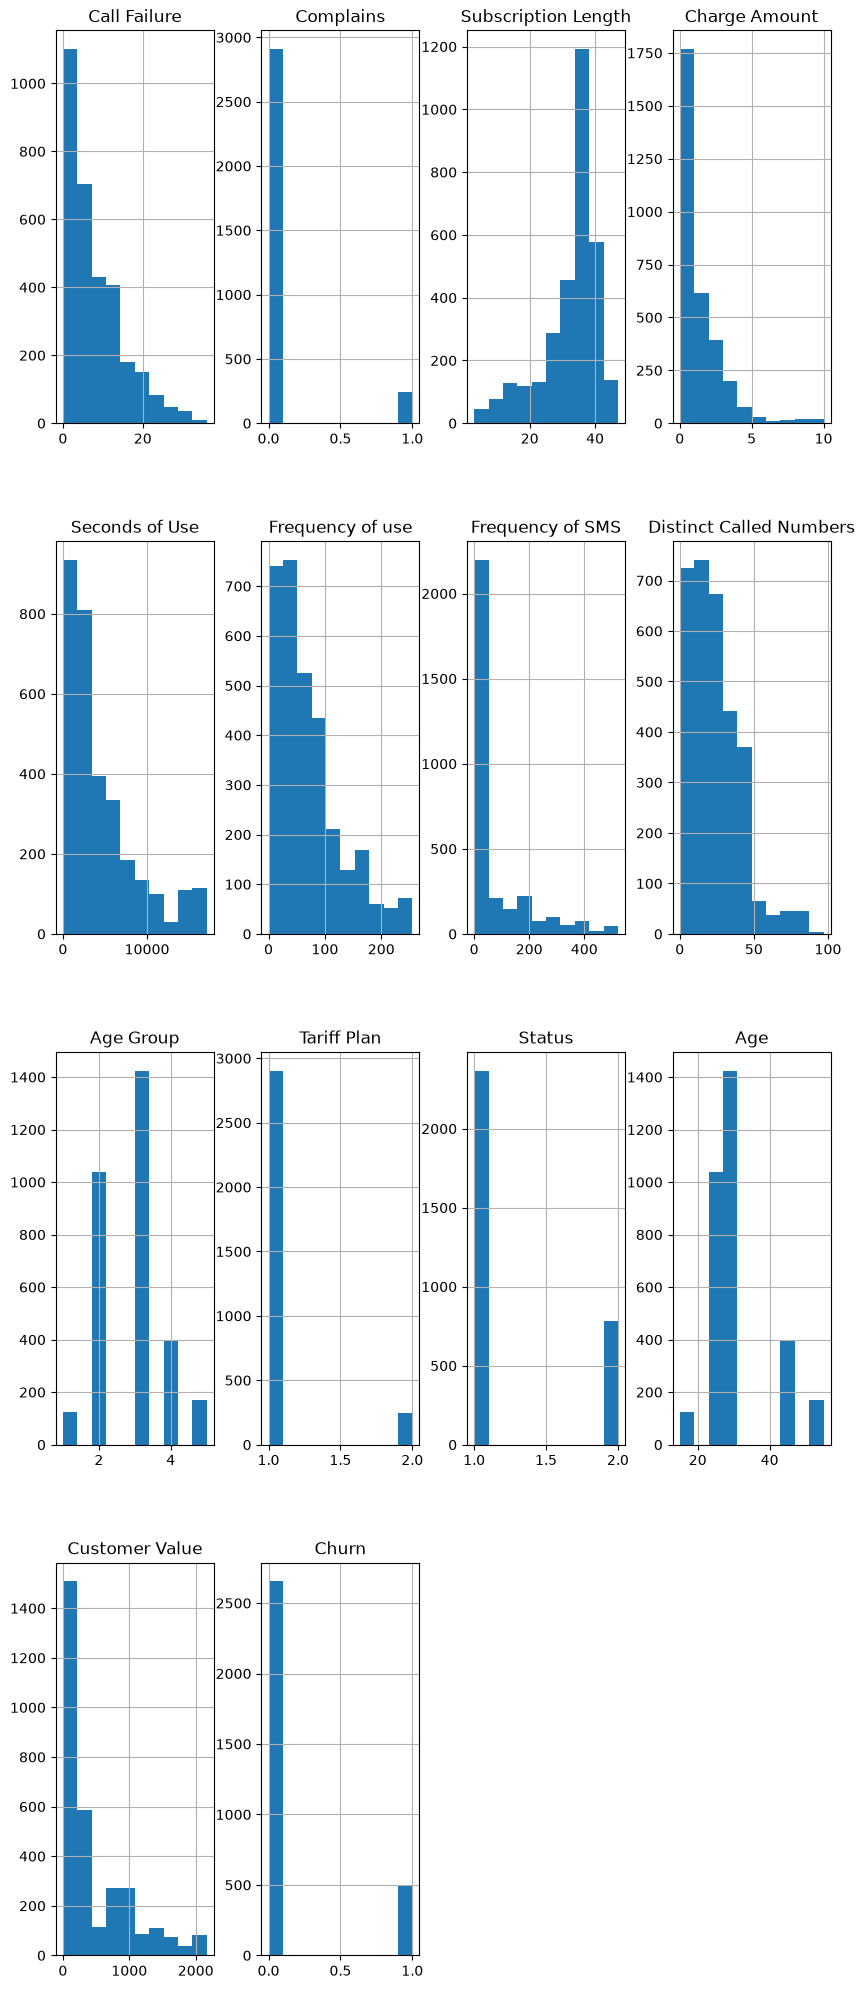

In [9]:
#visuallizing the data as histogram chart
fig, ax = plt.subplots(1, 1, figsize=(10,25))
customer_churn_data.hist(ax=ax)

All columns share one y axis in this boxplot, so the small scale features are flattened against `Seconds of Use`. Plotting the continuous columns separately, or on a log scale, makes them readable.

**Outliers are kept.** A customer with 522 SMS is a heavy user, not a typo. Removing real extremes would narrow the population the model learns from, and the most active customers are informative for churn. The alternatives if they caused problems would be a log transform or capping, not deletion.

<Axes: >

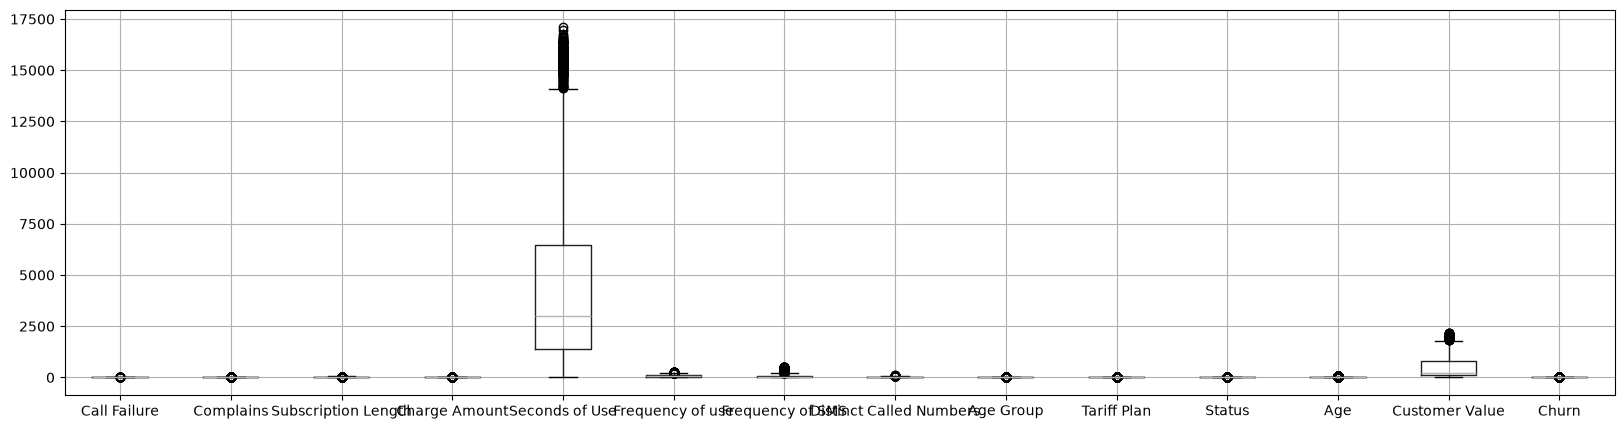

In [10]:
#plotting data in boxplot chart
fig, ax = plt.subplots(1,1,figsize=(20, 5))
customer_churn_data.boxplot()

<Axes: >

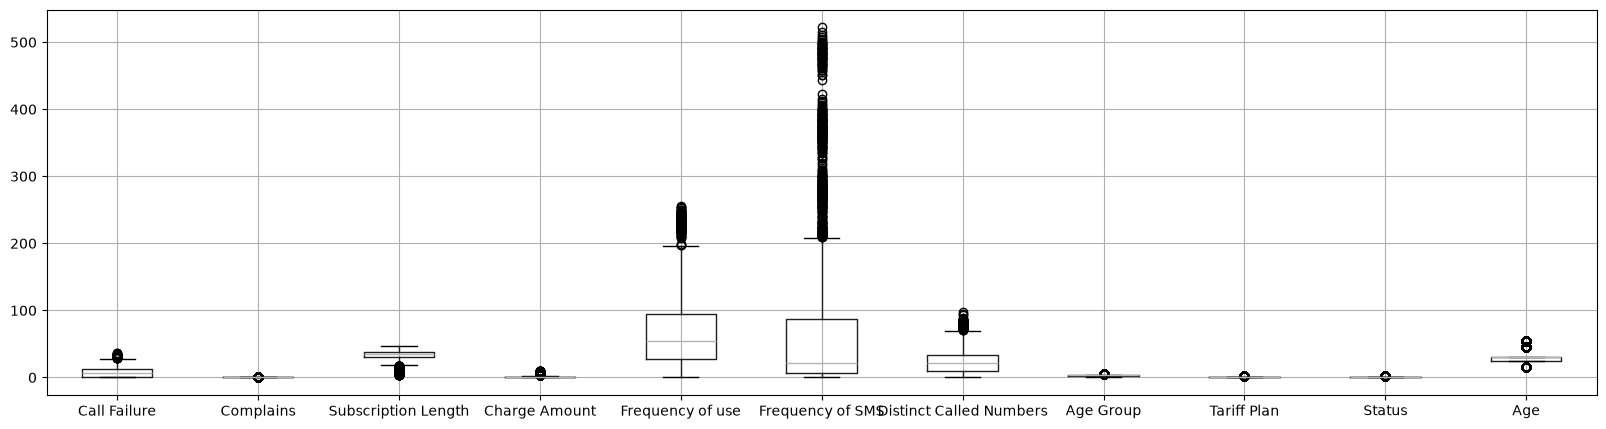

In [11]:
features1 = [
    'Call Failure',
    'Complains',
    'Subscription Length',
    'Charge Amount',
    'Frequency of use',
    'Frequency of SMS',
    'Distinct Called Numbers',
    'Age Group',
    'Tariff Plan',
    'Status',
    'Age',
    #'Customer Value'
]
fig, ax = plt.subplots(1,1,figsize=(20, 5))
customer_churn_data[features1].boxplot()

### 1.7 Correlation between features

`Churn` is dropped so this matrix shows feature to feature relationships only. Correlation **with the target** is looked at separately in section 1.8.

Two limits of Pearson correlation matter later:

1. It only measures **linear** association, so a value near 0 does not mean two features are unrelated.
2. High correlation between features damages **interpretation** more than prediction. Logistic regression coefficients become unstable and can flip sign, KNN double counts the repeated information in its distance calculation, and tree feature importance gets split between the pair.

In [12]:
#Here im doing a correlation analysis, but first i drop Churn, the target feature.
correlation = customer_churn_data.drop('Churn', axis=1).corr()
correlation
#This correlation table is hard to read, so i will add a heatmap to it.

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value
Call Failure,1.000000,0.152879,0.169737,0.589028,0.501607,0.573349,-0.022282,0.504058,0.050406,0.192285,-0.114645,0.041758,0.121225
Complains,0.152879,1.000000,-0.020286,-0.033948,-0.104952,-0.090774,-0.111633,-0.058199,0.019976,0.001140,0.271405,0.003298,-0.132895
Subscription Length,0.169737,-0.020286,1.000000,0.078789,0.124618,0.106534,0.076318,0.092009,0.021453,-0.159680,0.142841,-0.002430,0.109565
Charge Amount,0.589028,-0.033948,0.078789,1.000000,0.446738,0.379096,0.091533,0.415198,0.279679,0.324232,-0.356269,0.278955,0.169428
Seconds of Use,0.501607,-0.104952,0.124618,0.446738,1.000000,0.946489,0.102123,0.676536,0.020060,0.133593,-0.460618,0.020843,0.415087
Frequency of use,0.573349,-0.090774,0.106534,0.379096,0.946489,1.000000,0.100019,0.736114,-0.032544,0.206452,-0.454752,-0.028350,0.401572
Frequency of SMS,-0.022282,-0.111633,0.076318,0.091533,0.102123,0.100019,1.000000,0.079650,-0.053719,0.195686,-0.296164,-0.092798,0.924877
Distinct Called Numbers,0.504058,-0.058199,0.092009,0.415198,0.676536,0.736114,0.079650,1.000000,0.020941,0.172079,-0.413039,0.051037,0.284807
Age Group,0.050406,0.019976,0.021453,0.279679,0.020060,-0.032544,-0.053719,0.020941,1.000000,-0.150593,0.002506,0.960758,-0.183481
Tariff Plan,0.192285,0.001140,-0.159680,0.324232,0.133593,0.206452,0.195686,0.172079,-0.150593,1.000000,-0.164143,-0.119426,0.252298


In [13]:
#correlation as a heatmap, makes it much easier to read and understand.
correlation.style.background_gradient(cmap='coolwarm')

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value
Call Failure,1.000000,0.152879,0.169737,0.589028,0.501607,0.573349,-0.022282,0.504058,0.050406,0.192285,-0.114645,0.041758,0.121225
Complains,0.152879,1.000000,-0.020286,-0.033948,-0.104952,-0.090774,-0.111633,-0.058199,0.019976,0.001140,0.271405,0.003298,-0.132895
Subscription Length,0.169737,-0.020286,1.000000,0.078789,0.124618,0.106534,0.076318,0.092009,0.021453,-0.159680,0.142841,-0.002430,0.109565
Charge Amount,0.589028,-0.033948,0.078789,1.000000,0.446738,0.379096,0.091533,0.415198,0.279679,0.324232,-0.356269,0.278955,0.169428
Seconds of Use,0.501607,-0.104952,0.124618,0.446738,1.000000,0.946489,0.102123,0.676536,0.020060,0.133593,-0.460618,0.020843,0.415087
Frequency of use,0.573349,-0.090774,0.106534,0.379096,0.946489,1.000000,0.100019,0.736114,-0.032544,0.206452,-0.454752,-0.028350,0.401572
Frequency of SMS,-0.022282,-0.111633,0.076318,0.091533,0.102123,0.100019,1.000000,0.079650,-0.053719,0.195686,-0.296164,-0.092798,0.924877
Distinct Called Numbers,0.504058,-0.058199,0.092009,0.415198,0.676536,0.736114,0.079650,1.000000,0.020941,0.172079,-0.413039,0.051037,0.284807
Age Group,0.050406,0.019976,0.021453,0.279679,0.020060,-0.032544,-0.053719,0.020941,1.000000,-0.150593,0.002506,0.960758,-0.183481
Tariff Plan,0.192285,0.001140,-0.159680,0.324232,0.133593,0.206452,0.195686,0.172079,-0.150593,1.000000,-0.164143,-0.119426,0.252298


Three pairs stand out, and they are three different situations:

| Pair | r | Situation |
|---|---|---|
| `Age`, `Age Group` | 0.96 | the same variable encoded twice |
| `Frequency of SMS`, `Customer Value` | 0.93 | one is derived from the other |
| `Seconds of Use`, `Frequency of use` | 0.95 | genuinely different quantities that co-move |

**`Age` and `Age Group`.** The scatter below shows 5 points out of 25 possible combinations, so each age maps to exactly one group with no exceptions. Spearman correlation is 1.0, while Pearson is only 0.96 because the age gaps (10, 5, 15, 10) are uneven while the group gaps are all 1. Pearson penalises that unevenness even though the mapping is perfect. **One of the two columns can be dropped with no loss.**

The plot is also heavily overplotted. All 3150 rows are drawn, but a single marker at `Age` 30 hides 1425 of them, and the marker for 123 customers looks identical to the marker for 1425.

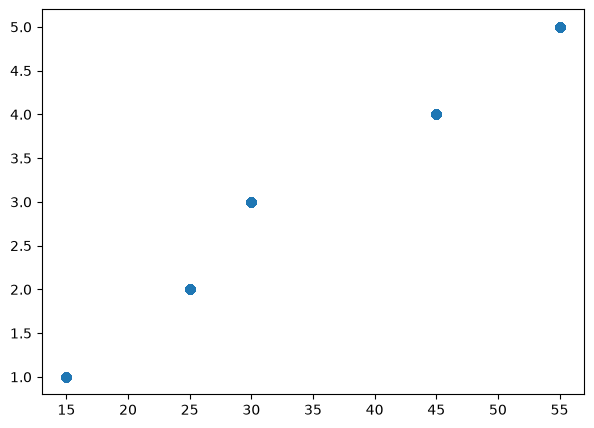

In [14]:
#We see that age and age group are highly correlated, same goes for Frequency of use and Seconds of use.
#Lets take a closer look with scatter.
fig, ax = plt.subplots(figsize=(7, 5))

plt.scatter(customer_churn_data['Age'], customer_churn_data['Age Group'])
#A scatter is not really for fit for this 2 features
#because Age Group only has 5 values, against age it will only show 5 distinct points.
#The plot becomes heavily overplotted.


Grouping first and passing the counts to `s` fixes the overplotting. The pattern is `groupby` then `size` then `reset_index`, which plots groups instead of rows.

`s` is marker **area**, not radius, so count maps to area. That is the honest encoding, since mapping count to radius would exaggerate differences by squaring them.

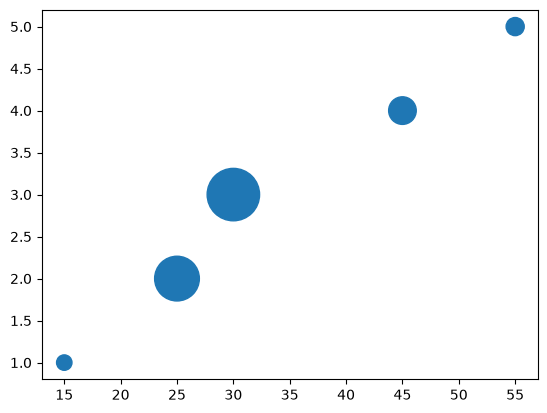

In [15]:
#i use a count based pattern, a so caled "bubble scatter" and plot groups instead of rows.
 
counts = customer_churn_data.groupby(['Age', 'Age Group']).size().reset_index(name='n')
plt.scatter(counts['Age'], counts['Age Group'], s=counts['n'])



`Seconds of Use` against `Frequency of use`, r = 0.95.

Unlike `Age` and `Age Group` these are different quantities, total talk time and number of calls, so **both are kept**. They correlate because people who call more also talk more, which is a real behavioural relationship rather than an encoding artefact.

Their ratio is average call duration, a signal neither column contains alone. 200 short calls and 200 long calls look similar on both raw features but describe different customers.

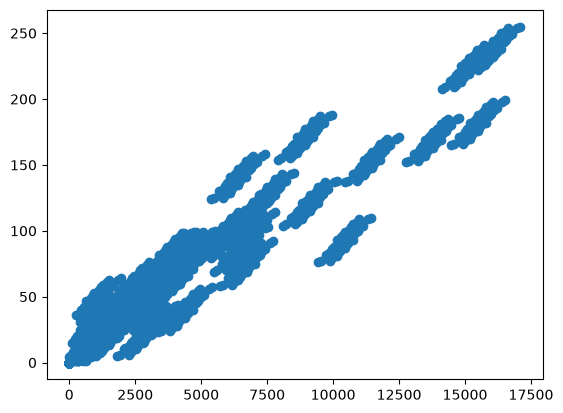

In [16]:
#Another highly correlated pair.
plt.scatter(customer_churn_data['Seconds of Use'], customer_churn_data['Frequency of use'])

`Seconds of Use` against `Subscription Length` has a Pearson correlation of only 0.12, yet the scatter shows obvious cluster and boundary structure.

**This is the clearest demonstration in the notebook that low correlation does not mean no relationship.** Pearson only detects straight line trends, so curves, clusters and boundaries are invisible to it.

Two effects are visible:

- A **ceiling**. Subscriptions under 10 months reach at most 8932 seconds, while 30 to 40 month subscriptions reach 17090. Short subscriptions cannot accumulate high usage, which creates the empty lower right region.
- **Cohort clusters**. The diagonal streaks line up with `Age Group` and `Charge Amount` bands, consistent with semi synthetic data construction.

The plot is also overplotted at default settings. Adding `alpha` shows the true density peak sits at low usage with 32 to 40 months subscribed.



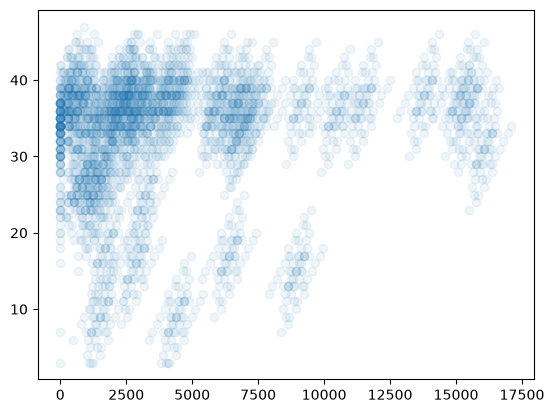

In [17]:
#investigating two not correlated features

plt.scatter(customer_churn_data['Seconds of Use'], customer_churn_data['Subscription Length'], alpha=0.07)


### 1.8 Target balance and leakage check

`Churn` is 84.3% class 0 and 15.7% class 1

Predicting class 0 for every customer scores 84.3% accuracy while catching zero churners, so recall and F1 are both 0. That majority class result is the baseline every model has to beat, and it is why accuracy alone is not a sufficient measure here.

**Leakage check.** `Complains` and `Status` correlate with `Churn` at 0.53 and 0.50, far above every other feature. Leakage is a question about timing and causality, not correlation strength:

- `Complains` is kept as a legitimate predictor. A complaint is an event that plausibly happens before churn and causes it, and a real telecom would know who complained.
- `Status` (active / non active) is flagged as a possible leakage risk. Inactivity may be a symptom of churn recorded at the same time as the target rather than a precursor. It is not a perfect proxy, since 63% of non active customers did not churn, so it is kept, but an ablation with and without it is reported in the evaluation section.


<Axes: xlabel='Churn'>

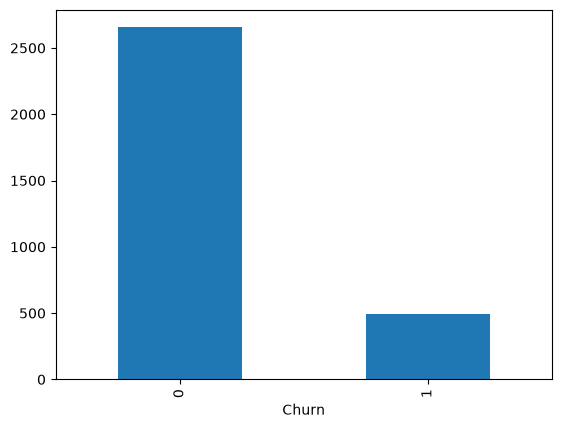

In [18]:
#showing the distribution of the target feature. 
customer_churn_data['Churn'].value_counts().plot.bar()

## 2. Data Processing

Summary of the decisions taken in the EDA:

| Item | Decision |
|---|---|
| Double spaced headers | normalised with regex |
| Missing values | none, no imputation |
| Duplicate rows | kept, they are dormant customers not errors |
| Outliers | kept, they are heavy users not errors |
| `Age` and `Age Group` | redundant, one can be dropped |
| `Seconds of Use` and `Frequency of use` | both kept, different quantities |
| `Status` | kept, flagged for a leakage ablation |

### 2.1 Features and target

`Churn` is separated from the predictors. Keeping one global `features` frame and slicing it by split index later means the feature selection logic lives in one place.

In [19]:
# Separating the dataset into features and targets

features = customer_churn_data.drop('Churn', axis=1)
targets = customer_churn_data['Churn']

### 2.2 Scaling

Mean normalisation subtracts the mean and divides by the standard deviation, putting every feature on a comparable scale. This is needed because of the four orders of magnitude difference found in section 1.4. It matters for KNN, where raw `Seconds of Use` would dominate every distance, and for logistic regression coefficients. Tree based models are unaffected by monotonic rescaling.


In [20]:
# Mean normalization using pandas
features_normalized = (features - features.mean())/features.std()

### 2.3 Train, validation and test split

60% training, 20% validation, 20% test. One `global_random_state` variable is used so the split is reproducible and there is a single place to change the seed.

**Stratification.** `groupby('Churn').sample(frac=...)` samples within each class separately, which preserves the 15.7% churn rate in all three sets. Without it a plain random split could hand the test set a different class balance by chance, and the metrics would then describe a different population than the one trained on. The printed proportions confirm 0.8429 / 0.1571 in all three.

| Set | n | Used for |
|---|---|---|
| train | 1890 | fitting the models |
| validation | 630 | comparing hyperparameter settings |
| test | 630 | evaluated once, at the very end |




In [21]:
global_random_state = 13

In [22]:
# Splitting
#60% for training
train_indices = customer_churn_data.groupby('Churn').sample(frac=0.60, random_state=global_random_state).index
train_features = features_normalized.iloc[train_indices]
train_targets = targets.iloc[train_indices]

#20% for validation
testvalidation_dataset = customer_churn_data.drop(train_indices, axis=0)
validation_incdices = testvalidation_dataset.groupby('Churn').sample(frac=0.5, random_state=global_random_state).index

validation_features = features_normalized.iloc[validation_incdices]
validation_targets = targets.iloc[validation_incdices]

#20% for testing
test_indices = testvalidation_dataset.drop(validation_incdices, axis=0).index
test_features = features_normalized.iloc[test_indices]
test_targets = targets.iloc[test_indices]



## 3. Models and Hyperparameter Tuning

I train three baseline models: a decision tree, Gaussian Naive Bayes, and a linear model (`SGDClassifier`). I picked models that fail in different ways so the comparison has something to say.

`validation()` prints all four metrics for training and validation side by side. The gap between the two columns is what shows overfitting.



In [23]:
#Functions to perform evaluation 

# Used to evaluate hyperparameter tuning
def validation(model):
    train_predictions = model.predict(train_features)
    validation_predictions = model.predict(validation_features)
    print(f'Training Accuracy: {accuracy_score(train_targets, train_predictions):.2f} Validation: {accuracy_score(validation_targets, validation_predictions):.2f}')    
    print(f'Training Precision: {precision_score(train_targets, train_predictions):.2f} Validation: {precision_score(validation_targets, validation_predictions):.2f}')    
    print(f'Training Recall: {recall_score(train_targets, train_predictions):.2f} Validation: {recall_score(validation_targets, validation_predictions):.2f}')    
    print(f'Training F1: {f1_score(train_targets, train_predictions):.2f} Validation: {f1_score(validation_targets, validation_predictions):.2f}')    
# Used for final testing
def test(model):
    train_predictions = model.predict(train_features)
    validation_predictions = model.predict(validation_features)
    test_predictions = model.predict(test_features)
    print(f'Training Accuracy: {accuracy_score(train_targets, train_predictions):.2f} Validation: {accuracy_score(validation_targets, validation_predictions):.2f} Testing: {accuracy_score(test_targets, test_predictions):.2f}')    
    print(f'Training Precision: {precision_score(train_targets, train_predictions):.2f} Validation: {precision_score(validation_targets, validation_predictions):.2f} Testing: {precision_score(test_targets, test_predictions):.2f}')    
    print(f'Training Recall: {recall_score(train_targets, train_predictions):.2f} Validation: {recall_score(validation_targets, validation_predictions):.2f} Testing: {recall_score(test_targets, test_predictions):.2f}')    
    print(f'Training F1: {f1_score(train_targets, train_predictions):.2f} Validation: {f1_score(validation_targets, validation_predictions):.2f} Testing: {f1_score(test_targets, test_predictions):.2f}')    

### 3.1 Decision tree

Starting with default hyperparameters to get a reference point before tuning anything.

In [24]:
#Training a decision tree with def hyperparam

dt_default = DecisionTreeClassifier(random_state=global_random_state)
dt_default.fit(train_features, train_targets)
validation(dt_default)

Training Accuracy: 0.99 Validation: 0.92
Training Precision: 0.98 Validation: 0.72
Training Recall: 0.98 Validation: 0.80
Training F1: 0.98 Validation: 0.76


Training F1 0.98 against validation 0.76. That gap is overfitting: the tree memorised the training set instead of learning a general pattern. Left unrestricted it grows to depth 19, deep enough to build leaves describing individual customers.

Accuracy hides most of the damage. It drops 0.99 to 0.92, while F1 drops 0.98 to 0.76. Accuracy is dominated by the 84% majority class, which is the easy part. Precision and recall only look at churners.

It is still a useful model. Validation F1 0.76 beats the majority baseline (F1 0.00) and beats a hand written rule on `Complains` or `Status` (F1 around 0.63), so the extra complexity is earning something.

#### Tuning max_depth

`max_depth` is the main complexity control, so it decides how much the tree can memorise. I print training and validation together so I can see where underfitting turns into overfitting.

In [25]:
#Testing multiple depths to see the best one.
#Validation F1 of depth 15 being the best one with 0.78
for depth in [2, 3, 5, 6, 7, 8, 10, 12, 15]:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=global_random_state)
    dt.fit(train_features, train_targets)
    print(f"\nmax_depth={depth}")
    validation(dt)



max_depth=2
Training Accuracy: 0.90 Validation: 0.90
Training Precision: 0.90 Validation: 0.97
Training Recall: 0.41 Validation: 0.37
Training F1: 0.57 Validation: 0.54

max_depth=3
Training Accuracy: 0.91 Validation: 0.89
Training Precision: 0.75 Validation: 0.70
Training Recall: 0.62 Validation: 0.57
Training F1: 0.68 Validation: 0.63

max_depth=5
Training Accuracy: 0.94 Validation: 0.92
Training Precision: 0.86 Validation: 0.80
Training Recall: 0.77 Validation: 0.68
Training F1: 0.81 Validation: 0.73

max_depth=6
Training Accuracy: 0.95 Validation: 0.93
Training Precision: 0.99 Validation: 0.89
Training Recall: 0.71 Validation: 0.63
Training F1: 0.83 Validation: 0.73

max_depth=7
Training Accuracy: 0.96 Validation: 0.93
Training Precision: 0.92 Validation: 0.81
Training Recall: 0.80 Validation: 0.71
Training F1: 0.86 Validation: 0.76

max_depth=8
Training Accuracy: 0.97 Validation: 0.92
Training Precision: 0.93 Validation: 0.77
Training Recall: 0.89 Validation: 0.74
Training F1: 0.

| max_depth | Train F1 | Val F1 |
|---|---|---|
| 2 | 0.57 | 0.54 |
| 3 | 0.68 | 0.63 |
| 5 | 0.81 | 0.73 |
| 6 | 0.83 | 0.73 |
| 7 | 0.86 | 0.76 |
| 8 | 0.91 | 0.75 |
| 10 | 0.94 | 0.75 |
| 12 | 0.97 | 0.77 |
| 15 | 0.98 | 0.78 |
| None | 0.98 | 0.76 |

Depth 2 and 3 underfit. Training F1 is low as well, so the model cannot fit data it has already seen, which is a different problem from overfitting.

Validation F1 climbs steeply to about depth 7, then flattens between 0.75 and 0.78 instead of falling. There is no clear overfitting penalty at the deep end even though the training gap keeps widening.

Depth 15 scored highest here, but I repeated the sweep across several random splits to check. Across splits it is tied with depth 12 and with an unrestricted tree, so that difference was run to run variation rather than a real effect. Depth 12 is my choice: same performance as the best, smaller train/validation gap, and shallow enough to plot.

I also tried `criterion`, which made no measurable difference (under 0.005, well inside the noise), and `class_weight`, which does not raise F1 but trades precision for recall. 

### 3.2 Naive Bayes

Naive Bayes assumes two things: features are conditionally independent given the class, and (for `GaussianNB`) each feature is normally distributed within each class. My EDA already showed both are false for this dataset, so I expect it to do badly and want to see how it fails.

In [26]:
#default naive bayes classifier
default_nb = GaussianNB()
default_nb.fit(train_features, train_targets)
validation(default_nb)

Training Accuracy: 0.72 Validation: 0.71
Training Precision: 0.35 Validation: 0.34
Training Recall: 0.93 Validation: 0.93
Training F1: 0.51 Validation: 0.50


Accuracy 0.71, precision 0.34, recall 0.93, F1 0.50.

Training and validation are identical across all four metrics. No gap at all, so this is not overfitting. It is high bias: the model is too constrained to represent the pattern, and more data or regularisation will not help.

Accuracy 0.71 is actually **below** the 0.84 I get by predicting no churn for everyone, but F1 went from 0.00 to 0.50. The model is finding churners, it is just flagging far too many people.

Both assumptions are broken by my data:

- **Independence.** `Age` and `Age Group` correlate at 0.96, `Seconds of Use` and `Frequency of use` at 0.95, `Frequency of SMS` and `Customer Value` at 0.93. Naive Bayes multiplies these as if they were separate evidence, so it counts the same information twice and becomes overconfident. That is why recall is 0.93 while precision is 0.34.
- **Normality.** `Complains` is 98.5% zeros, `Tariff Plan` 91%, `Status` 84.5%. `GaussianNB` fits a bell curve to each of these, which is meaningless for a binary column.

In [27]:
#
nb_smoothing_1 = GaussianNB(var_smoothing=1e-1)
nb_smoothing_1.fit(train_features, train_targets)
validation(nb_smoothing_1)

Training Accuracy: 0.73 Validation: 0.73
Training Precision: 0.36 Validation: 0.36
Training Recall: 0.93 Validation: 0.93
Training F1: 0.52 Validation: 0.52


`var_smoothing` moved F1 by 0.01. It adds a floor to the variance estimates for numerical stability, so it cannot repair a distributional mismatch. Another null result.

What does help is fixing the assumptions rather than the hyperparameters. Applying `log1p` to the skewed usage features makes them closer to Gaussian and raises F1 to about 0.61 with accuracy back to 0.84, and dropping the redundant columns adds a little more. Raising the decision threshold well above 0.5 also helps, which is itself evidence of the overconfidence caused by the independence violation.

Worth noting this is a model specific preprocessing step. The decision tree is unaffected by `log1p` because it only uses the ordering of values, not their spacing.

### 3.3 Linear model (SGDClassifier)

`SGDClassifier` fits a linear decision boundary using stochastic gradient descent. With the default `loss="hinge"` it is a linear SVM. This is the model that most needs the scaled features, since a single set of coefficients has to be comparable across columns.

It is also the model most damaged by the class imbalance, so `class_weight` turns out to matter more than any other hyperparameter here.

In [28]:
sgd_default = SGDClassifier(random_state=global_random_state, class_weight="balanced")
sgd_default.fit(train_features, train_targets)
validation(sgd_default)

Training Accuracy: 0.76 Validation: 0.77
Training Precision: 0.39 Validation: 0.40
Training Recall: 0.90 Validation: 0.91
Training F1: 0.54 Validation: 0.56


Accuracy 0.77, precision 0.40, recall 0.91, F1 0.56.

`class_weight="balanced"` is doing most of the work. Without it the same model scores precision 0.95 and recall 0.36, catching only a third of churners while looking respectable on accuracy (0.90).

Why it matters so much here: 84% of the training rows are class 0, so the loss is minimised by mostly predicting class 0. A linear model has one boundary for the whole feature space, so that pressure drags the boundary away from churners everywhere at once. `balanced` weights each churner by about 5.4 (`n_samples / (n_classes * n_class_samples)`) so both classes contribute equally to the loss, and the boundary moves back.

The tradeoff is clear in the numbers. Recall goes 0.36 to 0.91, precision goes 0.95 to 0.40, and accuracy drops below the 0.84 majority baseline. Training and validation are again nearly identical, so like Naive Bayes this is bias, not overfitting.

Two things I could still improve: `loss="log_loss"` would give logistic regression with probability outputs, which would let me tune the threshold instead of only the weights, and it would make the coefficients easier to interpret.

In [29]:
sgd_alpha_1 = SGDClassifier(random_state=global_random_state, alpha=1e-2, class_weight="balanced")
sgd_alpha_1.fit(train_features, train_targets)
validation(sgd_alpha_1)

Training Accuracy: 0.84 Validation: 0.83
Training Precision: 0.49 Validation: 0.49
Training Recall: 0.86 Validation: 0.89
Training F1: 0.62 Validation: 0.63


`alpha` controls regularisation strength, which shrinks the coefficients. With balancing on it trades a little recall for precision:

| alpha | acc | prec | rec | F1 |
|---|---|---|---|---|
| 1e-5 | 0.83 | 0.48 | 0.86 | 0.61 |
| 1e-4 (default) | 0.77 | 0.40 | 0.91 | 0.56 |
| 1e-3 | 0.80 | 0.44 | 0.92 | 0.59 |
| 1e-2 | 0.83 | 0.49 | 0.89 | 0.63 |
| 1e-1 | 0.83 | 0.49 | 0.89 | 0.63 |

F1 improves from 0.56 to 0.63 and then flattens above 1e-2. Compared to `class_weight`, which moved F1 by 0.10 and recall by 0.55, `alpha` is a minor knob. That is the same pattern as the decision tree, where `max_depth` mattered and `criterion` did not: hyperparameters differ a lot in leverage, and it is worth finding out which ones matter before spending time on a grid.

### Summary so far

| Model | Val Accuracy | Val Precision | Val Recall | Val F1 |
|---|---|---|---|---|
| Majority class baseline | 0.84 | 0.00 | 0.00 | 0.00 |
| Rule: `Complains` or `Status` | 0.84 | 0.49 | 0.89 | 0.63 |
| Decision tree (depth 12) | 0.93 | 0.77 | 0.78 | **0.77** |
| Gaussian Naive Bayes | 0.71 | 0.34 | 0.93 | 0.50 |
| SGDClassifier (alpha 1e-2, balanced) | 0.83 | 0.49 | 0.89 | 0.63 |

The decision tree wins clearly, and it is the only model that is good at precision and recall at the same time. The reason is explainable rather than accidental: it makes no assumption about how features are distributed, and it handles the correlated pairs by simply not splitting twice on the same information.

The other two both end up in the same corner, high recall and low precision, for different reasons. Naive Bayes gets there by violating its independence assumption, which makes it overconfident and too eager to flag. The linear model gets there because balancing pushes its single boundary toward the minority class, and it cannot separate the classes any better than a straight line allows. The cluster structure I found in `Seconds of Use` against `Subscription Length` is exactly the kind of shape a linear boundary cannot follow and a tree can.

Worth noting that the balanced linear model lands on the same F1 as the simple two-feature rule from section 1.8 (0.63). It is not adding anything over an `if` statement, which is a useful reminder to compare against baselines rather than only against other models.

If missing a churner were far more costly than a false alarm, Naive Bayes (recall 0.93) or the balanced linear model (0.89) would be preferable to the tree (0.78), despite the lower F1. Which metric to optimise is a business decision, not a statistical one.

**Still to do:** fix the scaling leakage from section 2.2, move the confusion matrix and precision/recall calls out of the tuning section, and run the three tuned models once on the test set.

## 4. Final Evaluation on the Test Set

Everything above used the validation set. The test set has not been touched at any point, so it is still an honest estimate of performance on unseen data.

Now that the hyperparameters are chosen I evaluate once, and these are the numbers I report. Nothing below this point feeds back into model selection.

Final configurations:

| Model | Setting | Why |
|---|---|---|
| Decision tree | `max_depth=12` | simplest depth statistically tied with the best on validation |
| Gaussian Naive Bayes | defaults | `var_smoothing` had no measurable effect |
| SGDClassifier | `alpha=1e-2`, `class_weight="balanced"` | balancing was the only parameter that mattered |

In [30]:
# Fit the three chosen models on the training set
final_tree = DecisionTreeClassifier(max_depth=12, random_state=global_random_state)
final_tree.fit(train_features, train_targets)

final_nb = GaussianNB()
final_nb.fit(train_features, train_targets)

final_sgd = SGDClassifier(alpha=1e-2, class_weight="balanced", random_state=global_random_state)
final_sgd.fit(train_features, train_targets)

final_models = [("Decision tree (depth 12)", final_tree),
                ("Gaussian Naive Bayes", final_nb),
                ("SGDClassifier (balanced)", final_sgd)]

In [31]:
# Majority class baseline on the test set, for comparison
baseline_predictions = np.zeros(len(test_targets))
print('Majority class baseline')
print(f'  Accuracy: {accuracy_score(test_targets, baseline_predictions):.2f}'
      f'  Precision: 0.00  Recall: 0.00  F1: 0.00\n')

# test() prints train, validation and test together, so the
# validation to test drop is visible
for name, model in final_models:
    print(name)
    test(model)
    print()

Majority class baseline
  Accuracy: 0.84  Precision: 0.00  Recall: 0.00  F1: 0.00

Decision tree (depth 12)
Training Accuracy: 0.99 Validation: 0.93 Testing: 0.96
Training Precision: 0.98 Validation: 0.77 Testing: 0.89
Training Recall: 0.96 Validation: 0.78 Testing: 0.82
Training F1: 0.97 Validation: 0.77 Testing: 0.85

Gaussian Naive Bayes
Training Accuracy: 0.72 Validation: 0.71 Testing: 0.77
Training Precision: 0.35 Validation: 0.34 Testing: 0.40
Training Recall: 0.93 Validation: 0.93 Testing: 0.93
Training F1: 0.51 Validation: 0.50 Testing: 0.56

SGDClassifier (balanced)
Training Accuracy: 0.84 Validation: 0.83 Testing: 0.86
Training Precision: 0.49 Validation: 0.49 Testing: 0.53
Training Recall: 0.86 Validation: 0.89 Testing: 0.86
Training F1: 0.62 Validation: 0.63 Testing: 0.65



### 4.1 Confusion matrices

The four metrics are summaries of these four numbers, so the matrix shows what the model actually did rather than a ratio. the bottom row is churners the model caught and missed, the top right is false alarms.

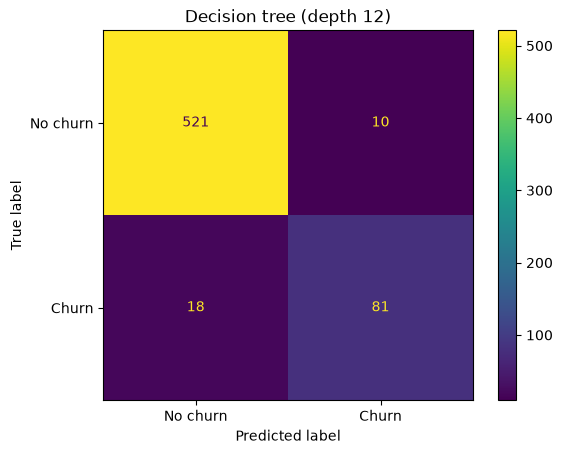

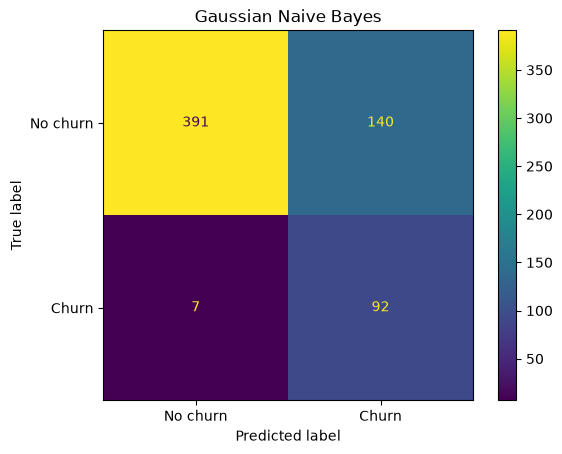

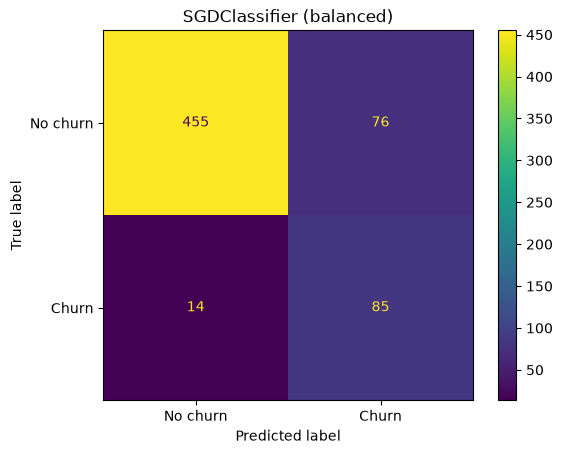

In [32]:
# A function for plotting a confusion matrix for a model
# on test data
def show_confusion(model, name):
    predictions = model.predict(test_features)
    confusion = confusion_matrix(test_targets, predictions)
    display = ConfusionMatrixDisplay(confusion, display_labels=['No churn', 'Churn'])
    display.plot()
    plt.title(name)
    plt.show()

for name, model in final_models:
    show_confusion(model, name)

### 4.2 Precision and recall curves

A precision/recall curve shows the whole tradeoff instead of a single operating point. Moving the decision threshold away from the default 0.5 moves along this curve, so a model can be made more or less eager to flag churn without retraining it.

This matters here because the classes are imbalanced and 0.5 is only a default, not a choice I made. A curve that stays high for longer is the better model regardless of where the threshold happens to sit.

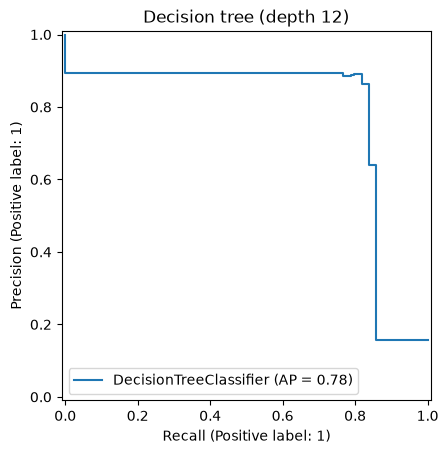

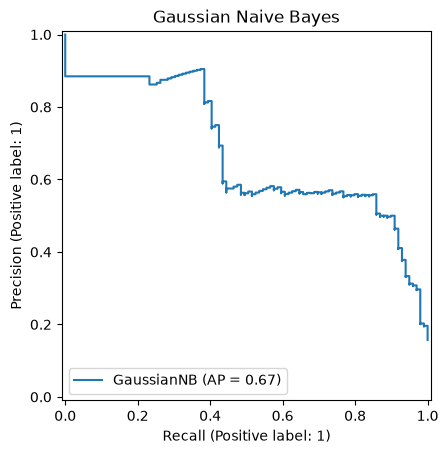

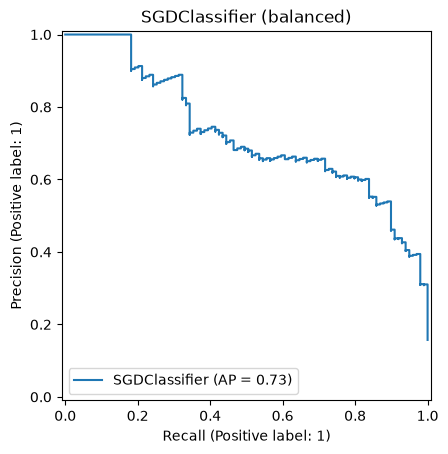

In [33]:
# Function for plotting a precision/recall curve for a model on test data
def show_precisionrecall(model, name):
    PrecisionRecallDisplay.from_estimator(model, test_features, test_targets)
    plt.title(name)
    plt.show()

for name, model in final_models:
    show_precisionrecall(model, name)